# Bengaluru House Price Prediction
## Session 1: setup, load and first-pass cleaning

**Objective.** Load the raw Bengaluru house-price data, understand it, and reduce it to a clean frame that holds only the columns that can feed the model (`location`, `size`, `total_sqft`, `bath`, `price`) with no missing values.

**Target.** `price`, in **lakhs of INR** (1 lakh = 100,000 INR). The `price` column stays in lakhs throughout the project; nothing is converted in this session.

**Out of scope for this session.** Cleaning `total_sqft` (ranges and unit strings, Session 2), encoding, scaling and the train/test split.

## 1. Setup and load

`df_raw` holds the data exactly as loaded and is never modified; every cleaning step works on a new frame.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__}")

Python 3.13.18 | pandas 3.1.0


In [2]:
# Where the CSV can be: the notebook sits in model/, so the data folder is one level up
# (or just data/ if Jupyter was started from the repository root). Kaggle's own file name is
# Bengaluru_House_Data.csv; the same data also circulates as bengaluru_house_prices.csv.
locations = [
    Path("../data/bengaluru_house_prices.csv"),
    Path("../data/Bengaluru_House_Data.csv"),
    Path("data/bengaluru_house_prices.csv"),
    Path("data/Bengaluru_House_Data.csv"),
]

csv_path = None
for path in locations:
    if path.exists():
        csv_path = path
        break

if csv_path is None:
    raise FileNotFoundError("No CSV found. Save the Kaggle file in the repository's data/ folder (see the README).")

df_raw = pd.read_csv(csv_path)
print(f"Loaded {csv_path}")

Loaded ../data/bengaluru_house_prices.csv


## 2. Inspect the raw data

In [3]:
print(df_raw.shape)
display(df_raw.head())
df_raw.dtypes

(13320, 9)


,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


area_type           str
availability        str
location            str
size                str
society             str
total_sqft          str
bath            float64
balcony         float64
price           float64
dtype: object

Text columns appear as `object` in pandas below 3 and as `str` from pandas 3 on; either way they are non-numeric. `total_sqft` is one of them: it holds ranges and unit strings, so it stays untouched until Session 2.

In [4]:
null_counts = df_raw.isnull().sum()
pd.DataFrame({"nulls": null_counts, "pct_missing": (null_counts / len(df_raw) * 100).round(2)})

,nulls,pct_missing
area_type,0,0.00
availability,0,0.00
location,1,0.01
size,16,0.12
society,5502,41.31
total_sqft,0,0.00
bath,73,0.55
balcony,609,4.57
price,0,0.00


In [5]:
df_raw["area_type"].value_counts()

area_type
Super built-up  Area    8790
Built-up  Area          2418
Plot  Area              2025
Carpet  Area              87
Name: count, dtype: int64

In [6]:
# Observation only: nothing is removed in this session.
n_repeats = int(df_raw.duplicated().sum())
print(f"Rows that exactly repeat an earlier row: {n_repeats:,} ({n_repeats / len(df_raw):.2%})")

Rows that exactly repeat an earlier row: 529 (3.97%)


### Findings

Every figure the brief expected holds: 13,320 rows and 9 columns; `society` is missing for 41.3% of the rows (5,502), `balcony` for 609, `bath` for 73, `size` for 16 and `location` for 1. `area_type`, `availability`, `total_sqft` and `price` have no nulls. `price` is numeric; `total_sqft` is text.

529 rows exactly repeat an earlier row (all nine raw columns). They are left in place; whether to remove them is decided in Session 4, before the train/test split (see the open items at the end).

## 3. Drop columns that cannot feed the model

Evidence for each decision, computed from the raw data:

In [7]:
DROP_COLS = ["area_type", "availability", "society", "balcony"]

evidence = pd.DataFrame({
    "dtype": df_raw[DROP_COLS].dtypes.astype(str),
    "pct_missing": (df_raw[DROP_COLS].isnull().mean() * 100).round(1),
    "n_unique": df_raw[DROP_COLS].nunique(),
    "top_values": pd.Series({c: df_raw[c].value_counts().head(3).to_dict() for c in DROP_COLS}),
})
with pd.option_context("display.max_colwidth", None):
    display(evidence)

,dtype,pct_missing,n_unique,top_values
area_type,str,0.0,4,"{'Super built-up Area': 8790, 'Built-up Area': 2418, 'Plot Area': 2025}"
availability,str,0.0,81,"{'Ready To Move': 10581, '18-Dec': 307, '18-May': 295}"
society,str,41.3,2688,"{'GrrvaGr': 80, 'PrarePa': 76, 'Sryalan': 59}"
balcony,float64,4.6,4,"{2.0: 5113, 1.0: 4897, 3.0: 1672}"


**Justification for each drop**

- **`area_type`**: it changes what `total_sqft` measures (super built-up, built-up, carpet or plot area), so it may well carry signal; it is left out of this first baseline as a judgment call, not because it is unusable, and it is logged in the README as a known limitation to test in Session 5.
- **`availability`**: it mixes the labels "Ready To Move" and "Immediate Possession" with possession-month strings such as "18-Dec" (81 distinct values in all), so it describes when a unit can be occupied rather than what the property is, and it cannot be used without parsing dates.
- **`society`**: 41.3% of its values are missing and the rest hold 2,688 distinct names, so it would be a sparse, high-cardinality categorical that cannot be encoded reliably.
- **`balcony`**: it is a minor amenity count with only four distinct values (0 to 3) and 609 missing entries, so dropping it avoids imputing values for otherwise complete rows and keeps the baseline on the core features.

In [8]:
df = df_raw.drop(columns=DROP_COLS)
assert len(df) == len(df_raw)  # dropping columns never removes rows
df.shape

(13320, 5)

## 4. Remaining nulls in `location`, `size` and `bath`

Count them, look at where they sit, and check that they do not cluster before dropping them.

In [9]:
CORE_NULL_COLS = ["location", "size", "bath"]

nulls_now = df.isnull().sum()
display(nulls_now.to_frame("nulls"))
assert set(nulls_now[nulls_now > 0].index) <= set(CORE_NULL_COLS), "unexpected nulls outside location/size/bath"

,nulls
location,1
size,16
total_sqft,0
bath,73
price,0


In [10]:
null_flags = df[CORE_NULL_COLS].isnull()
null_mask = null_flags.any(axis=1)
n_null_rows = int(null_mask.sum())

print(f"Rows with at least one null in {CORE_NULL_COLS}: {n_null_rows} "
      f"({n_null_rows / len(df):.2%} of {len(df):,})")

# Which of the three columns are null together? (True = null)
null_flags[null_mask].value_counts().rename("rows").reset_index()

Rows with at least one null in ['location', 'size', 'bath']: 74 (0.56% of 13,320)


,location,size,bath,rows
0,False,False,True,57
1,False,True,True,16
2,True,False,False,1


In [11]:
# Raw rows (dropped columns still visible) for the null `location` and `size` cases.
df_raw[df["location"].isnull() | df["size"].isnull()]

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
568,Super built-up Area,Ready To Move,NaN,3 BHK,Grare S,1600,3.0,2.0,86.000
579,Plot Area,Immediate Possession,Sarjapur Road,NaN,Asiss B,1200 - 2400,NaN,NaN,34.185
1775,Plot Area,Immediate Possession,IVC Road,NaN,Orana N,2000 - 5634,NaN,NaN,124.000
2264,Plot Area,Immediate Possession,Banashankari,NaN,NaN,2400,NaN,NaN,460.000
2809,Plot Area,Immediate Possession,Sarjapur Road,NaN,AsdiaAr,1200 - 2400,NaN,NaN,28.785
2862,Plot Area,Immediate Possession,Devanahalli,NaN,Ajleyor,1500 - 2400,NaN,NaN,46.800
5333,Plot Area,Immediate Possession,Devanahalli,NaN,Emngs S,2100 - 5405,NaN,NaN,177.115
6423,Plot Area,Immediate Possession,Whitefield,NaN,SRniaGa,2324,NaN,NaN,26.730
6636,Plot Area,Immediate Possession,Jigani,NaN,S2enste,1500,NaN,NaN,25.490
6719,Plot Area,Immediate Possession,Hoskote,NaN,SJowsn,800 - 2660,NaN,NaN,28.545


### What the null rows have in common

A read-only look: `total_sqft` is not modified here (cleaning it is Session 2); the cell only tests whether each value is written as a range such as "2100 - 2850".

In [12]:
is_range = df["total_sqft"].str.contains(r"\d\s*-\s*\d")

groups = {
    "all rows": pd.Series(True, index=df.index),
    "any null row": null_mask,
    "bath only": null_flags["bath"] & ~null_flags["size"] & ~null_flags["location"],
    "size and bath": null_flags["size"],
    "location only": null_flags["location"],
}
rows = []
for name, m in groups.items():
    rows.append({
        "group": name,
        "rows": int(m.sum()),
        "total_sqft is a range": int(is_range[m].sum()),
        "% range": round(is_range[m].mean() * 100, 1),
        "% balcony also missing": round(df_raw.loc[m, "balcony"].isnull().mean() * 100, 1),
        "% Plot Area": round(df_raw.loc[m, "area_type"].str.contains("Plot").mean() * 100, 1),
    })
pd.DataFrame(rows).set_index("group")

,rows,total_sqft is a range,% range,% balcony also missing,% Plot Area
group,,,,,
all rows,13320,201,1.5,4.6,15.2
any null row,74,57,77.0,98.6,21.6
bath only,57,49,86.0,100.0,0.0
size and bath,16,8,50.0,100.0,100.0
location only,1,0,0.0,0.0,0.0


### Do the null rows cluster?

The brief asks for a check by `location`: the table below lists the locations that hold the most null rows, with each location's null rate. The second table does the same by `area_type`, read from the raw frame because the column is already gone from `df`. Location names are not cleaned yet (that is the first job of Session 3), so spelling variants of one place count as separate locations here.

In [13]:
# Null rows per location, next to the number of listings the location has in total.
loc_null = df.loc[null_mask, "location"].value_counts()   # the one null location is skipped
by_location = pd.DataFrame({
    "null_rows": loc_null,
    "all_rows": df["location"].value_counts().loc[loc_null.index],
})
by_location["null_rate_%"] = (by_location["null_rows"] / by_location["all_rows"] * 100).round(1)

print(f"{loc_null.sum()} null rows have a known location, spread over {len(loc_null)} of the "
      f"{df['location'].nunique():,} locations in the data.")
by_location.head(10)

73 null rows have a known location, spread over 36 of the 1,305 locations in the data.


,null_rows,all_rows,null_rate_%
location,,,
Kanakpura Road,7,273,2.6
Sarjapur Road,7,399,1.8
Whitefield,6,540,1.1
Devanahalli,5,45,11.1
JP Nagar,5,72,6.9
Hennur,3,55,5.5
Yelahanka,3,213,1.4
Jakkur,3,71,4.2
KR Puram,3,91,3.3


In [14]:
# area_type is already dropped from df, but the raw frame still has it: diagnostic use only.
area_check = pd.DataFrame({
    "null_rows": df_raw.loc[null_mask, "area_type"].value_counts(),
    "all_rows": df_raw["area_type"].value_counts(),
}).fillna(0).astype(int)
area_check["null_rate_%"] = (area_check["null_rows"] / area_check["all_rows"] * 100).round(2)
exp_area = n_null_rows * area_check["all_rows"] / area_check["all_rows"].sum()  # expected if scattered at random
area_check["expected_if_random"] = exp_area.round(1)
area_check["lift"] = (area_check["null_rows"] / exp_area).round(2)
area_check.sort_values("null_rows", ascending=False)

,null_rows,all_rows,null_rate_%,expected_if_random,lift
area_type,,,,,
Super built-up Area,50,8790,0.57,48.8,1.02
Plot Area,16,2025,0.79,11.2,1.42
Built-up Area,8,2418,0.33,13.4,0.60
Carpet Area,0,87,0.00,0.5,0.00


### Findings: where the null rows sit

- **74 distinct rows are affected, not the 90 you get by adding the three column counts.** The nulls overlap: the 16 `size` nulls are all also `bath` nulls, 57 rows are null in `bath` only, and 1 row is null in `location` only.
- **Not one location.** 73 of the rows have a known location, spread over 36 of the 1,305 locations; the busiest two hold 7 each (9.6%). A few small locations have high null rates (Devanahalli 5 of 45 listings, JP Nagar 5 of 72, Hennur 3 of 55), but each rests on 3 to 5 rows, too few to say more.
- **The clearest pattern is listing type, not place.** The 16 `size` nulls are all Plot Area listings with availability "Immediate Possession". Of the 57 `bath`-only nulls, 49 (86%) have `total_sqft` written as a range, against 1.5% of all rows, and every `bath` null also lacks `balcony`.
- **By `area_type`** the null rate is 0.3% to 0.8% in each of the three large types (0 of 87 in Carpet Area). Plot Area is the only type clearly above its random share (16 null rows against about 11 expected): those are the 16 `size` nulls.

**Decision: drop these rows rather than impute them.** `location` has no sensible fill value, and `bath` is structurally tied to the bedroom count in `size`, so a median fill would invent data. The affected share is 0.56% of the rows. The drop also removes 57 of the 201 raw rows with a ranged `total_sqft`, so 144 remain for Session 2.

In [15]:
rows_before = len(df)
df = df.dropna()  # the index is deliberately not reset: it keeps each row traceable to its line in the raw CSV
rows_after = len(df)
assert rows_before - rows_after == n_null_rows  # exactly the rows flagged above

print(f"Rows before: {rows_before:,} | after: {rows_after:,} | removed: {rows_before - rows_after:,} "
      f"({(rows_before - rows_after) / rows_before:.2%})")

Rows before: 13,320 | after: 13,246 | removed: 74 (0.56%)


## 5. Final check of the Session 1 frame

In [16]:
assert list(df.columns) == ["location", "size", "total_sqft", "bath", "price"]
assert df.isnull().sum().sum() == 0

print(f"Final shape: {df.shape}")

null_summary = pd.DataFrame({"nulls_before": df_raw.isnull().sum()})
null_summary["nulls_after"] = df.isnull().sum()  # aligns on column name; a dropped column shows as <NA>
display(null_summary.astype("Int64"))
df.head()

Final shape: (13246, 5)


,nulls_before,nulls_after
area_type,0,<NA>
availability,0,<NA>
location,1,0
size,16,0
society,5502,<NA>
total_sqft,0,0
bath,73,0
balcony,609,<NA>
price,0,0


,location,size,total_sqft,bath,price
0,Electronic City Phase II,2 BHK,1056,2.0,39.07
1,Chikka Tirupathi,4 Bedroom,2600,5.0,120.00
2,Uttarahalli,3 BHK,1440,2.0,62.00
3,Lingadheeranahalli,3 BHK,1521,3.0,95.00
4,Kothanur,2 BHK,1200,2.0,51.00


## Session 2: feature engineering

**Objective.** Turn `size` and `total_sqft` into clean numeric features (`bhk`, and `total_sqft` as a float) and add `price_per_sqft`, so that Session 3 can start on `location`.

Each choice that changes which listings the model can see (the "RK" rows, the `total_sqft` ranges and unit strings) is argued from counts below and logged in the decision log at the end.

**Cautions for the whole session**

- `price_per_sqft` is built from the target (`price`). It must **never be a model input**; it exists only to spot outliers in Session 4.
- Nothing is removed because of an extreme value (`bhk`, `price_per_sqft` or anything else): extremes are reported and left in. The 529 repeated rows are left in too.

In [17]:
# Work on a copy: df (the Session 1 result) stays untouched, and df2 is its own frame.
df2 = df.copy()
df2.shape

(13246, 5)

### Step 1. `bhk` from `size`

`size` is text such as "2 BHK", "4 Bedroom" or "1 RK". The number in front is the bedroom count, so `str.extract` with the regular expression `^(\d+)` (digits at the start of the string) pulls it out. `extract` gives NaN for every row where the pattern does not match, so asserting that nothing is NaN proves that every row matched.

In [18]:
# What follows the number? (the brief says BHK, Bedroom and RK)
print(df2["size"].str.extract(r"^\d+\s*(\w+)", expand=False).value_counts().to_dict())

bhk_text = df2["size"].str.extract(r"^(\d+)", expand=False)
assert bhk_text.notna().all(), "some `size` values have no leading integer"
df2["bhk"] = bhk_text.astype(int)

print(f"bhk runs from {df2['bhk'].min()} to {df2['bhk'].max()}; "
      f"{(df2['bhk'] >= 10).sum()} rows have 10 or more; "
      f"2 and 3 BHK make up {df2['bhk'].isin([2, 3]).mean():.1%} of rows")
df2["bhk"].value_counts().sort_index().to_frame("rows").T

{'BHK': 10718, 'Bedroom': 2515, 'RK': 13}
bhk runs from 1 to 43; 26 rows have 10 or more; 2 and 3 BHK make up 78.2% of rows


bhk,1,2,3,4,5,6,7,8,9,10,11,12,13,14,16,18,19,27,43
rows,649,5527,4832,1395,353,221,100,89,54,14,4,1,1,1,1,1,1,1,1


**The 13 "RK" rows.** "1 RK" means one room plus a kitchen: there is no separate bedroom, so `bhk` has no obvious value for them. The evidence is the rows themselves and how they compare with 1 BHK flats.

In [19]:
is_rk = df2["size"].str.contains("RK")
is_1bhk = df2["size"].str.match(r"1\s*BHK")

for name, mask in [("1 RK", is_rk), ("1 BHK", is_1bhk)]:
    print(f"{name:<6}{mask.sum():>4} rows | median price {df2.loc[mask, 'price'].median():5.2f} lakh | "
          f"median bath {df2.loc[mask, 'bath'].median()}")

df2.loc[is_rk, ["location", "size", "total_sqft", "bath", "price"]]

1 RK    13 rows | median price 25.25 lakh | median bath 1.0
1 BHK  531 rows | median price 32.00 lakh | median bath 1.0


,location,size,total_sqft,bath,price
24,Thanisandra,1 RK,510,1.0,25.25
782,Thanisandra,1 RK,445,1.0,28.00
1363,Thanisandra,1 RK,510,1.0,25.25
2486,Bhoganhalli,1 RK,296,1.0,22.89
2557,Anekal,1 RK,351,1.0,16.00
2788,Rachenahalli,1 RK,440,1.0,28.00
4876,Electronic City,1 RK,435,1.0,19.50
5079,Whitefield,1 RK,905,1.0,52.00
5285,Rachenahalli,1 RK,385 - 440,1.0,19.80
6586,Electronics City Phase 1,1 RK,360,1.0,16.90


**Decision: keep the 13 "RK" rows and give them `bhk = 1`.** All 13 are "1 RK" with one bathroom and a small area (the largest is 905 sqft), and their median price (25.25 lakh) is below that of 1 BHK flats (32.00 lakh), so they belong at the bottom of the bedroom scale, next to 1 BHK. Dropping them would remove a whole listing type for 13 rows (0.10% of the data), and `bhk = 0` would create a value that occurs only 13 times. The cost is that the model cannot tell a 1 RK from a 1 BHK. Logged as decision 7.

### Step 2. `total_sqft` as a number

`total_sqft` is text. `pd.to_numeric(..., errors="coerce")` converts what is a plain number and turns everything else into NaN instead of raising an error. That sorts the column into three groups: plain numbers, ranges ("2100 - 2850") and unit strings ("34.46Sq. Meter"). Each group gets its own rule, and the rules for the ranges and the unit strings change which listings the model sees, so each is argued below.

In [20]:
as_number = pd.to_numeric(df2["total_sqft"], errors="coerce")   # plain numbers -> float; everything else -> NaN
is_plain = as_number.notna()
is_range = df2["total_sqft"].str.contains(r"\d\s*-\s*\d")
is_unit = ~is_plain & ~is_range
assert not (is_plain & is_range).any()                           # no row is counted twice

print(f"plain numbers {is_plain.sum():,} | ranges {is_range.sum()} | unit strings {is_unit.sum()} "
      f"| total {is_plain.sum() + is_range.sum() + is_unit.sum():,} of {len(df2):,} rows")

plain numbers 13,056 | ranges 144 | unit strings 46 | total 13,246 of 13,246 rows


**Ranges become their midpoint.** Split each range at the dash into a lower and an upper end, check that both ends are numbers, and average them. The midpoint is the usual convention, but it hides how wide a range is, so the widest ones are shown.

In [21]:
ends = df2.loc[is_range, "total_sqft"].str.split("-", expand=True)   # one column per end
assert ends.shape[1] == 2, "a range has more than one dash"
low = pd.to_numeric(ends[0], errors="coerce")
high = pd.to_numeric(ends[1], errors="coerce")
assert low.notna().all() and high.notna().all(), "a range end is not a number"
assert (high >= low).all(), "a range runs downwards"

midpoint = (low + high) / 2
spread = high - low
print(f"Median spread of the {len(spread)} ranges: {spread.median():.0f} sqft")

widest = pd.DataFrame({
    "total_sqft": df2.loc[is_range, "total_sqft"],
    "spread": spread,
    "upper / lower": (high / low).round(2),
})
widest.nlargest(5, "spread")

Median spread of the 144 ranges: 160 sqft


,total_sqft,spread,upper / lower
122,3067 - 8156,5089.00,2.66
5940,1349 - 3324,1975.00,2.46
672,3090 - 5002,1912.00,1.62
3174,2249.81 - 4112.19,1862.38,1.83
1694,4000 - 5249,1249.00,1.31


**Unit strings.** 46 rows give a number followed by a unit. The regular expression `^([\d.]+)\s*(.+)$` splits each of them into the number and the unit text, and the per-unit counts decide what to do with them.

In [22]:
units = df2.loc[is_unit, "total_sqft"].str.extract(r"^([\d.]+)\s*(.+)$")   # column 0: the number, column 1: the unit text
units.columns = ["value", "unit"]
assert units.notna().all().all(), "a unit string did not match number + unit"
units["value"] = pd.to_numeric(units["value"])

units.groupby("unit")["value"].agg(["count", "min", "max"]).sort_values("count", ascending=False)

,count,min,max
unit,,,
Sq. Meter,17,24.00,3040.0
Sq. Yards,15,45.00,2940.0
Acres,8,1.25,30.0
Guntha,2,24.00,38.0
Cents,2,3.00,1500.0
Grounds,1,1.00,1.0
Perch,1,4125.00,4125.0


In [23]:
CONVERT = {"Sq. Meter": 10.7639, "Sq. Yards": 9}    # square feet in one of each unit
converted = units[units["unit"].isin(CONVERT)]
left_out = units[~units["unit"].isin(CONVERT)]
print(f"convert {len(converted)} rows, leave out {len(left_out)} rows")

# The rows that would be left out:
df2.loc[left_out.sort_values("unit").index, ["location", "total_sqft", "bath", "price"]]

convert 32 rows, leave out 14 rows


,location,total_sqft,bath,price
1019,Marathi Layout,5.31Acres,1.0,110.0
1086,Narasapura,30Acres,2.0,29.5
6333,Harohalli,2.09Acres,2.0,200.0
7334,Kanakpura Road,2Acres,1.0,125.0
7607,Bommenahalli,15Acres,3.0,217.0
7726,Kanakpura Road,1.26Acres,1.0,125.0
10488,2 Bedroom Furnished Farm House in Kolar Road,1.25Acres,2.0,200.0
11615,arudi,6Acres,2.0,80.0
5453,Kannur,3Cents,6.0,75.0
7001,Thyagaraja Nagar,1500Cents,6.0,290.0


**Decision: convert Sq. Meter (× 10.7639) and Sq. Yards (× 9), and drop the other 14 rows.**

- Square metres and square yards have exact, universal conversion factors (1 m² = 10.7639 sq ft, 1 yd² = 9 sq ft), so these 32 rows (17 + 15) become square feet without guessing.
- The other 14 rows (8 Acres, 2 Cents, 2 Guntha, 1 Perch, 1 Grounds) are land-parcel units. Acres are farmland scale: the smallest listing here, 1.25 acres, is already 54,450 sq ft. Cents, guntha, perch and ground are defined differently from region to region. The rows also look like plots rather than flats ("4125Perch" with 9 bathrooms, "30Acres" for 29.5 lakh).
- The cost: 14 rows (0.11% of 13,246) go, so the model never sees listings quoted in those units.
- Alternatives not taken: dropping all 46 (0.35% of the rows) would also discard 32 ordinary listings; converting every unit needs regional definitions that are hard to defend.

In [24]:
# Fill each group of rows. .loc[row labels] = values lines the values up by row label.
sqft = as_number.copy()                                                           # plain numbers; the rest are NaN so far
sqft.loc[midpoint.index] = midpoint                                               # ranges -> midpoint
sqft.loc[converted.index] = converted["value"] * converted["unit"].map(CONVERT)   # Sq. Meter / Sq. Yards -> sq ft

# Whatever is still NaN must be exactly the unit rows that are deliberately left out.
assert set(sqft.index[sqft.isna()]) == set(left_out.index)

rows_before = len(df2)
# .copy() makes df2 its own frame; without it pandas can warn (SettingWithCopyWarning) when we assign to a filtered slice.
df2 = df2[sqft.notna()].copy()
df2["total_sqft"] = sqft[df2.index]
assert df2["total_sqft"].isna().sum() == 0

print(f"rows before {rows_before:,} | after {len(df2):,} | removed {rows_before - len(df2)}")

rows before 13,246 | after 13,232 | removed 14


### Step 3. `price_per_sqft`

`price` is in **lakhs** of INR and `total_sqft` is in square feet, so `price × 100,000 / total_sqft` is INR per square foot. Leaving out the × 100,000 would give lakhs per sqft, with typical values around 0.05. The arithmetic is vectorized: pandas applies it to whole columns at once, which gives the same numbers as `df2.apply(..., axis=1)` calling a Python function on every row, only much faster.

Reminder: this column is derived from the target, so it is never a model input.

In [25]:
df2["price_per_sqft"] = df2["price"] * 100_000 / df2["total_sqft"]

# Plausibility check on the first row, by hand.
row = df2.iloc[0]
print(f"{row['location']}: {row['price']} lakh x 100,000 / {row['total_sqft']:,.0f} sqft "
      f"= {row['price_per_sqft']:,.0f} INR per sqft")

# Same check for the rows converted from Sq. Meter / Sq. Yards: are they in line with the rest?
conv = df2.loc[converted.index, "price_per_sqft"]
print(f"{len(conv)} converted rows: median {conv.median():,.0f}, min {conv.min():,.0f}, max {conv.max():,.0f} "
      f"| all rows: median {df2['price_per_sqft'].median():,.0f}")

Electronic City Phase II: 39.07 lakh x 100,000 / 1,056 sqft = 3,700 INR per sqft
32 converted rows: median 4,855, min 405, max 98,765 | all rows: median 5,438


### Step 4. `describe()` and one histogram

The new columns, summarised and drawn. Nothing is cleaned on the basis of this step.

In [26]:
pps = df2["price_per_sqft"]
display(df2[["bhk", "total_sqft", "price_per_sqft"]].describe().round(1))
pps.quantile([0.01, 0.05, 0.95, 0.99]).round(0).to_frame("price_per_sqft").T

,bhk,total_sqft,price_per_sqft
count,13232.0,13232.0,13232.0
mean,2.8,1564.5,7922.8
std,1.3,1304.8,106601.3
min,1.0,1.0,267.8
25%,2.0,1100.0,4265.7
50%,3.0,1275.0,5437.9
75%,3.0,1675.0,7323.3
max,43.0,52272.0,12000000.0


,0.01,0.05,0.95,0.99
price_per_sqft,2546.0,3100.0,15321.0,23740.0


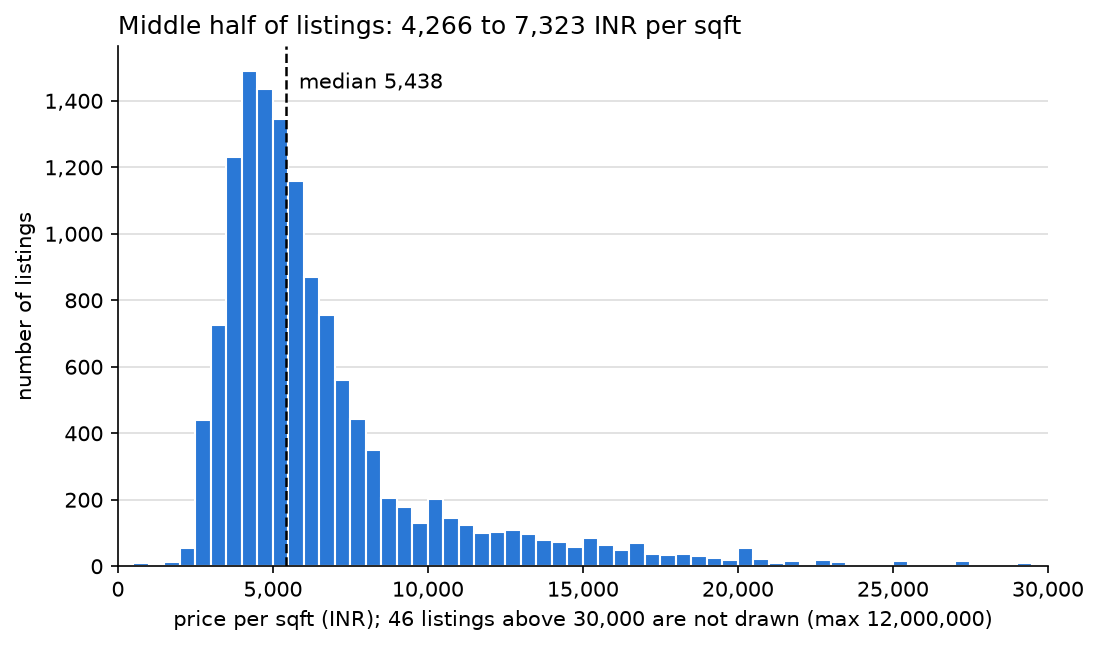

In [27]:
CAP = 30_000    # the x-axis stops here so the bulk of the data is readable; rows above it stay in the data
n_beyond = int((pps > CAP).sum())

fig, ax = plt.subplots(figsize=(8, 4.5), dpi=150)
ax.hist(pps, bins=60, range=(0, CAP), color="#2a78d6", edgecolor="white")
ax.axvline(pps.median(), color="black", linestyle="--", linewidth=1.2)
ax.text(pps.median() + 400, ax.get_ylim()[1] * 0.95, f"median {pps.median():,.0f}", va="top")

ax.set_title(f"Middle half of listings: {pps.quantile(0.25):,.0f} to {pps.quantile(0.75):,.0f} INR per sqft", loc="left")
ax.set_xlabel(f"price per sqft (INR); {n_beyond} listings above {CAP:,} are not drawn (max {pps.max():,.0f})")
ax.set_ylabel("number of listings")
ax.set_xlim(0, CAP)
ax.xaxis.set_major_formatter(lambda x, pos: f"{x:,.0f}")   # thousands separators on the tick labels
ax.yaxis.set_major_formatter(lambda y, pos: f"{y:,.0f}")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#dddddd")
ax.set_axisbelow(True)
plt.show()

In [28]:
# Extreme values: reported, not removed.
cols = ["location", "total_sqft", "bath", "price", "bhk", "price_per_sqft"]
print("Highest price_per_sqft:")
display(df2.nlargest(5, "price_per_sqft")[cols].round(1))
print("Lowest price_per_sqft:")
display(df2.nsmallest(5, "price_per_sqft")[cols].round(1))
print("Highest bhk:")
display(df2.nlargest(5, "bhk")[cols].round(1))
print(f"price_per_sqft below 1,000: {(pps < 1000).sum()} rows | above 20,000: {(pps > 20000).sum()} rows")

Highest price_per_sqft:


,location,total_sqft,bath,price,bhk,price_per_sqft
4086,Sarjapur Road,1.0,4.0,120.0,4,12000000.0
4972,Srirampuram,5.0,7.0,115.0,7,2300000.0
349,Suragajakkanahalli,11.0,3.0,74.0,3,672727.3
1122,Grihalakshmi Layout,24.0,2.0,150.0,5,625000.0
11558,Whitefield,60.0,4.0,218.0,4,363333.3


Lowest price_per_sqft:


,location,total_sqft,bath,price,bhk,price_per_sqft
1894,Nelamangala,52272.0,2.0,140.0,3,267.8
674,Yelahanka,35000.0,3.0,130.0,3,371.4
7520,Doddaballapur,11840.3,2.0,48.0,3,405.4
5393,Doddabommasandra,42000.0,8.0,175.0,9,416.7
3228,Dodda Banaswadi,32722.3,5.0,140.0,5,427.8


Highest bhk:


,location,total_sqft,bath,price,bhk,price_per_sqft
4684,Munnekollal,2400.0,40.0,660.0,43,27500.0
1718,2Electronic City Phase II,8000.0,27.0,230.0,27,2875.0
3379,1Hanuman Nagar,2000.0,16.0,490.0,19,24500.0
11559,1Kasavanhalli,1200.0,18.0,200.0,18,16666.7
3609,Koramangala Industrial Layout,10000.0,16.0,550.0,16,5500.0


price_per_sqft below 1,000: 17 rows | above 20,000: 238 rows


**What this shows**

- **The × 100,000 conversion is right.** The median is 5,438 INR per sqft and the middle half runs from 4,266 to 7,323: thousands of INR, as a Bengaluru flat should be. Leaving out the × 100,000 would give values near 0.05.
- **Long right tail.** The mean (7,923) sits well above the median, and 238 rows are above 20,000 (the 99th percentile is 23,740).
- **Implausible values at both ends.** 17 rows are below 1,000 INR per sqft. Eleven of them are plot-sized (11,840 to 52,272 sqft). The other six span 1,798 to 10,961 sqft, and two of those are ordinary home sizes with prices that look too low (BTM Layout: 1,798 sqft at 10 lakh; Begur: 2,400 sqft at 12 lakh). That is a different problem from the plots, and a rule on area would not catch it. The highest values come from tiny `total_sqft` entries: 1, 5, 11, 24 and 60 sqft for homes with 3 to 7 bedrooms, such as 120 lakh for 1 sqft = 12,000,000 INR per sqft. A few rows like these are why the standard deviation (106,601) is more than 13 times the mean.
- **Extreme `bhk`.** 26 rows have 10 or more bedrooms; the top five are 43, 27, 19, 18 and 16. The 43-bedroom row has 2,400 sqft and 40 bathrooms. Three of the five locations begin with a digit ("2Electronic City Phase II", "1Hanuman Nagar", "1Kasavanhalli"), which is a location-cleaning question for Session 3.
- **Converted unit rows.** Their median (4,855) is close to the overall median, so the two factors look right. Two of the five lowest values are large Sq. Meter plots (1,100 and 3,040 sq m), and the highest of the 32 is a 45 Sq. Yards listing with 6 bathrooms (98,765).

All of these rows are left in. Deciding which ones are real outliers is Session 4's job.

### Step 5. Drop `size`, then check the final frame

`size` is replaced by `bhk`, so it goes last, once the assertion in Step 1 has confirmed that `bhk` is complete. The assertion is repeated just before the drop.

In [29]:
assert df2["bhk"].notna().all()            # bhk is complete, so `size` is no longer needed
df2 = df2.drop(columns="size")

assert list(df2.columns) == ["location", "total_sqft", "bath", "price", "bhk", "price_per_sqft"]
assert df2.isnull().sum().sum() == 0
assert pd.api.types.is_float_dtype(df2["total_sqft"]) and pd.api.types.is_integer_dtype(df2["bhk"])

print(f"Final Session 2 shape: {df2.shape}")
display(df2.dtypes.to_frame("dtype").T)
df2.head()

Final Session 2 shape: (13232, 6)


,location,total_sqft,bath,price,bhk,price_per_sqft
dtype,str,float64,float64,float64,int64,float64


,location,total_sqft,bath,price,bhk,price_per_sqft
0,Electronic City Phase II,1056.0,2.0,39.07,2,3699.810606
1,Chikka Tirupathi,2600.0,5.0,120.00,4,4615.384615
2,Uttarahalli,1440.0,2.0,62.00,3,4305.555556
3,Lingadheeranahalli,1521.0,3.0,95.00,3,6245.890861
4,Kothanur,1200.0,2.0,51.00,2,4250.000000


## Session 3: location cleaning and dimensionality reduction

**Objective.** Reduce `location` from about 1,300 raw names to roughly 240 real locations plus one `other` bucket, with a documented threshold.

**Why.** One-hot encoding (Session 5) turns every distinct location into a column. With about 1,300 locations and 13,000 rows, most of those columns would be nearly empty and the model could not learn from them. Grouping rare locations keeps the feature matrix small.

**Cautions for the whole session**

- No rows are removed (asserted below); duplicates and outliers are still left in.
- `other` is a catch-all, not a place. It will hold about a fifth of the rows, and Session 6 decides how the website treats it.
- The threshold is a convention. Session 5 will test whether a different one changes the cross-validation score.
- Listing counts are computed on all rows, before the train/test split. That is a known limitation (see the README).
- `price_per_sqft` stays out of the features.

In [30]:
# Work on a copy: df2 (the Session 2 result) stays untouched.
df3 = df2.copy()
df3.shape

(13232, 6)

### Step 1. Normalize the names

Three clean-ups, in this order:

1. **Whitespace.** `str.split()` cuts a name at every run of whitespace (and drops the ends), and `str.join(" ")` glues the words back with a single space. This fixes "Sarjapur  Road" (two spaces).
2. **Case.** A casefolded copy of each name is the key, so "JP Nagar" and "jp nagar" count as one place.
3. **Trailing punctuation.** Names such as "Kudlu Village," end in a comma. The cell below shows which characters actually end names, so the clean-up covers what is there.

Each key then gets its most frequent spelling as the clean name, so the website can later show readable names ("JP Nagar", not "jp nagar").

In [31]:
# Strip and collapse whitespace: split() cuts at every run of whitespace and drops the ends,
# join(" ") glues the words back together with a single space.
ws = df3["location"].str.split().str.join(" ")

# Which characters end a name when they are not a letter or a digit? (counted in rows)
last_char = ws.str[-1]
last_char[~last_char.str.isalnum()].value_counts()

location
,    56
.     3
)     1
Name: count, dtype: int64

The commas (56 rows) and periods (3 rows) are trailing punctuation. The single `)` closes a bracket in "Kengeri Satellite Town ( BDA SITE)" and belongs to the name, so only commas, periods and the spaces in front of them are removed.

In [32]:
stripped = ws.str.rstrip(" ,.")                # remove trailing commas, periods and the spaces in front of them
assert (stripped.str.len() > 0).all()          # no name has become empty
key = stripped.str.casefold()                  # one key per place, whatever the capitalisation

# Each key gets its most frequent spelling as the clean name; transform() puts that spelling on every row of the key.
# If two spellings tie, mode() lists them in sorted order, so the pick is the same on every run.
df3["location"] = stripped.groupby(key).transform(lambda spellings: spellings.mode().iloc[0])
assert df3["location"].nunique() == key.nunique()      # exactly one clean name per key

n_spellings = stripped.groupby(key).nunique()          # how many spellings each key has
multi = n_spellings[n_spellings > 1].index
print(f"rows changed by the trailing-punctuation step: {(ws != stripped).sum()}")
print(f"{len(multi)} places are written in more than one way; the busiest has {key.value_counts().loc[multi].max()} listings")

rows changed by the trailing-punctuation step: 59
12 places are written in more than one way; the busiest has 9 listings


In [33]:
# Distinct names after each clean-up, and how the names split at 10 listings.
stages = {
    "raw": df2["location"],
    "strip + collapse whitespace": ws,
    "+ casefold": ws.str.casefold(),
    "+ trailing punctuation removed": key,
}
funnel = []
for step, names in stages.items():
    n = names.value_counts()                   # listings per name
    funnel.append({
        "step": step,
        "distinct names": len(n),
        "> 10: names": int((n > 10).sum()),
        "> 10: rows": int(n[n > 10].sum()),
        "<= 10: names": int((n <= 10).sum()),
        "<= 10: rows": int(n[n <= 10].sum()),
        "<= 10: % of rows": round(n[n <= 10].sum() / len(names) * 100, 1),
        "1 listing: names": int((n == 1).sum()),
    })
pd.DataFrame(funnel).set_index("step")

,distinct names,> 10: names,> 10: rows,<= 10: names,<= 10: rows,<= 10: % of rows,1 listing: names
step,,,,,,,
raw,1299,240,10334,1059,2898,21.9,476
strip + collapse whitespace,1288,240,10349,1048,2883,21.8,469
+ casefold,1276,240,10349,1036,2883,21.8,453
+ trailing punctuation removed,1266,240,10364,1026,2868,21.7,447


**What the clean-up did.** The distinct names fall from 1,299 to 1,288 (whitespace), 1,276 (case) and 1,266 (trailing punctuation). The number of locations with more than 10 listings stays at 240 at every stage, so the clean-up never changes which locations are named; it only moves rows into them, and the share of rows in locations with 10 or fewer listings goes from 21.9% to 21.7%. Case merging reduces the names but moves no rows across the threshold: the 12 places written in more than one way all have 9 or fewer listings.

Up to the case step the numbers are the brief's expected findings exactly: 240 locations with more than 10 listings covering 10,349 rows, 1,036 locations with 10 or fewer covering 2,883 rows (21.8%), and 453 locations with a single listing. The trailing-punctuation step moves 15 more rows into named locations (Sarjapur Road gains 8 and Whitefield 2), so the biggest locations below are Whitefield 537 and Sarjapur Road 400 where the brief had 535 and 392. The other three match: Electronic City 304, Kanakpura Road 264, Thanisandra 236.

### Step 2. Count listings per location

How many locations have 1, up to 5, up to 10 and up to 20 listings, and what share of the rows each threshold would move into `other`.

In [34]:
counts = df3["location"].value_counts()          # listings per clean location
print("Biggest locations:", counts.head(5).to_dict())

threshold_rows = []
for t in [1, 5, 10, 20]:
    small = counts[counts <= t]                  # the locations at or below the threshold
    threshold_rows.append({
        "threshold": f"<= {t}",
        "locations at or below": len(small),
        "named locations kept": len(counts) - len(small),
        "rows moved to other": int(small.sum()),
        "% of rows": round(small.sum() / len(df3) * 100, 1),
    })
pd.DataFrame(threshold_rows).set_index("threshold")

Biggest locations: {'Whitefield': 537, 'Sarjapur Road': 400, 'Electronic City': 304, 'Kanakpura Road': 264, 'Thanisandra': 236}


,locations at or below,named locations kept,rows moved to other,% of rows
threshold,,,,
<= 1,447,819,447,3.4
<= 5,880,386,1763,13.3
<= 10,1026,240,2868,21.7
<= 20,1123,143,4280,32.3


### Step 3. Pick a threshold and replace rare locations with `other`

**Decision: locations with 10 or fewer listings become `other`.** That is 1,026 of the 1,266 names and 2,868 rows (21.7%); the 240 locations with 11 or more listings keep their names, which makes 241 categories with `other`. A location with 10 listings gives the model at most 10 examples to learn from (fewer once rows are held out for testing), too few to estimate a location effect.

The alternatives in the table above: threshold 5 keeps 386 named locations (146 more columns once the locations are one-hot encoded) and moves 13.3% of the rows; threshold 20 keeps 143 and moves 32.3%, so nearly a third of the listings would lose their location; threshold 1 (only single listings) keeps 819 locations and moves 3.4%. Ten is the brief's default and a convention; Session 5 will test whether another value changes the cross-validation score.

In [35]:
THRESHOLD = 10
OTHER = "other"
assert OTHER not in counts.index                         # no real location is called "other"

listings = df3["location"].map(counts)                   # listings of each row's location, repeated on every row
df3.loc[listings <= THRESHOLD, "location"] = OTHER

n_named = int((counts > THRESHOLD).sum())
n_other = int((df3["location"] == OTHER).sum())
assert len(df3) == 13_232                                # no rows removed
assert list(df3.columns) == list(df2.columns)            # columns unchanged
assert df3["location"].notna().all()
assert df3["location"].nunique() == n_named + 1          # the named locations plus "other"

print(f"threshold {THRESHOLD}: {n_named} named locations + '{OTHER}' = {df3['location'].nunique()} categories")
print(f"'{OTHER}' holds {n_other:,} of {len(df3):,} rows ({n_other / len(df3):.1%})")
df3["location"].value_counts().head(6).to_frame("rows")

threshold 10: 240 named locations + 'other' = 241 categories
'other' holds 2,868 of 13,232 rows (21.7%)


,rows
location,
other,2868
Whitefield,537
Sarjapur Road,400
Electronic City,304
Kanakpura Road,264
Thanisandra,236


### Step 4. `other` compared with the named locations

Median `price_per_sqft` (INR) of the rows in `other` against all rows in named locations, with the quartiles for the spread.

In [36]:
is_other = df3["location"] == OTHER
by_group = df3.groupby(is_other)["price_per_sqft"].describe()[["count", "25%", "50%", "75%"]].round(0).astype(int)
by_group.index = ["named locations", "other"]      # groupby sorts False before True
by_group

,count,25%,50%,75%
named locations,10364,4221,5333,6978
other,2868,4444,5908,10000


**What this shows.** The median `price_per_sqft` of `other` is 5,908 INR against 5,333 for the named locations (10.8% higher), and its spread is much wider: the middle half of `other` runs from 4,444 to 10,000, against 4,221 to 6,978. With 2,868 rows, `other` is also the largest category, more than five times the largest named location (Whitefield, 537). It is a catch-all of many unrelated places, not a place: knowing that a listing is in `other` says little about its price. Session 6 decides how the website treats it.

### Step 5. Digit-glued names

Names such as "1Hanuman Nagar" and "2Electronic City Phase II" have a digit directly in front of a letter. Ordinals ("1st", "7th") also have that shape but are legitimate, so they are excluded. The names are listed, not edited.

In [37]:
# A digit directly followed by a letter, unless the letters are an ordinal suffix (1st, 2nd, 3rd, 7th).
# (?i) ignores case, \d is a digit, (?!...) means "not followed by", \b is a word boundary.
glued_pattern = r"(?i)\d(?!(?:st|nd|rd|th)\b)[a-z]"
glued = counts[counts.index.str.contains(glued_pattern)]       # clean name -> listings
print(f"{len(glued)} names match, covering {glued.sum()} rows ({glued.sum() / len(df3):.2%} of all rows)")
print(f"most listings of any of them: {glued.max()} (threshold {THRESHOLD}), so {int((glued > THRESHOLD).sum())} survive")

# Context: all names that start with a digit.
starts_with_digit = counts[counts.index.str.match(r"\d")]
ordinal = starts_with_digit.index.str.match(r"(?i)\d+(st|nd|rd|th)\b")
print(f"{len(starts_with_digit)} names start with a digit; {ordinal.sum()} are ordinals like '7th Phase JP Nagar'; "
      f"{int((starts_with_digit[ordinal] > THRESHOLD).sum())} of those survive the threshold")

# The matching rows. df3 now shows `other` in `location`, so the cleaned name is added as `name`.
glued_rows = df3.assign(name=stripped)[stripped.isin(glued.index)]
glued_rows[["name", "location", "bhk", "bath", "total_sqft", "price"]]

9 names match, covering 9 rows (0.07% of all rows)
most listings of any of them: 1 (threshold 10), so 0 survive
62 names start with a digit; 51 are ordinals like '7th Phase JP Nagar'; 10 of those survive the threshold


,name,location,bhk,bath,total_sqft,price
1718,2Electronic City Phase II,other,27,27.0,8000.0,230.0
3379,1Hanuman Nagar,other,19,16.0,2000.0,490.0
4105,Indranagar 100ft road defence colony,other,5,5.0,5800.0,80.0
4916,1Channasandra,other,14,15.0,1250.0,125.0
6034,1A Block Koramangala,other,4,4.0,2360.0,650.0
6621,BTM Layout 1stage 9th Main,other,7,6.0,600.0,138.0
7568,bsk 6th stage 2ad block near sri conversation ...,other,4,4.0,600.0,87.0
9935,1Hoysalanagar,other,13,13.0,5425.0,275.0
11559,1Kasavanhalli,other,18,18.0,1200.0,200.0


**What this shows**

- **Nine names match, covering 9 rows (0.07% of the data), with one listing each, so none survives the threshold.** All nine rows are in `other`, and no name was edited by hand.
- **Six of the nine start with a digit** (the pattern in the brief). Five of those six also have an extreme bedroom count: `bhk` 13 to 27 with a bathroom count close to it (for example "2Electronic City Phase II": 27 bedrooms, 27 bathrooms). Together with the digit glued to the name, these look like bad rows rather than just misnamed places; whether to remove them is a question for Session 4. The sixth, "1A Block Koramangala" (4 bedrooms), is a real block name.
- **The other three have a digit inside the name**: "100ft", "1stage" and "2ad". Their bedroom counts (4 to 7) are ordinary, and they look like free text with typos rather than leaked digits.
- **Digit-leading names in general.** 62 names start with a digit; 51 are ordinals such as "7th Phase JP Nagar", and 10 of those survive the threshold (the other 41 have 10 or fewer listings and go to `other`). The remaining 11 are the six glued names above plus five written with a space after the digit ("1 Giri Nagar", "1 Ramamurthy Nagar", "1 Annasandrapalya", "1 Immadihalli", "4 Bedroom Farm House in Bagalur"). Those five do not match the brief's rule, have one listing each, and also fall into `other`.

## Decision log (Sessions 1 to 3)

Each decision with its row impact, as seen while the notebook ran on this data.

| # | Session | Decision | Why | Rows before | Rows after | Rows removed |
|--:|:-------:|----------|-----|------------:|-----------:|-------------:|
| 1 | 1 | Drop `area_type` | Judgment call: changes what `total_sqft` measures; re-test in Session 5 | 13,320 | 13,320 | 0 |
| 2 | 1 | Drop `availability` | Possession label/month, not a property attribute | 13,320 | 13,320 | 0 |
| 3 | 1 | Drop `society` | Large share missing and very high-cardinality | 13,320 | 13,320 | 0 |
| 4 | 1 | Drop `balcony` | Minor amenity count; avoids imputing | 13,320 | 13,320 | 0 |
| 5 | 1 | Drop rows with a null in `location`, `size` or `bath` | `location` has no sensible fill value; `bath` is tied to bedroom count (`size`), so imputing would invent data | 13,320 | 13,246 | 74 |
| 6 | 2 | `bhk` = leading integer of `size` | Every row matched the pattern (asserted) | 13,246 | 13,246 | 0 |
| 7 | 2 | Keep the 13 "RK" rows, with `bhk = 1` | All are 1 RK with one bathroom and a small area; dropping them removes a listing type, and `bhk = 0` would be a value seen 13 times | 13,246 | 13,246 | 0 |
| 8 | 2 | `total_sqft` ranges become their midpoint (144 rows) | The usual convention; the widest range (3067 - 8156) is 5,089 sqft wide | 13,246 | 13,246 | 0 |
| 9 | 2 | Convert 32 unit-string rows to sqft (17 Sq. Meter × 10.7639, 15 Sq. Yards × 9) | Exact, universal factors | 13,246 | 13,246 | 0 |
| 10 | 2 | Drop the 14 other unit-string rows (8 Acres, 2 Cents, 2 Guntha, 1 Perch, 1 Grounds) | Land-parcel units: farmland scale or region-defined | 13,246 | 13,232 | 14 |
| 11 | 2 | Add `price_per_sqft` = `price` × 100,000 / `total_sqft` (INR per sqft) | For spotting outliers in Session 4 only; built from the target, so never a model input | 13,232 | 13,232 | 0 |
| 12 | 2 | Drop `size` | Replaced by `bhk`, which is complete | 13,232 | 13,232 | 0 |
| 13 | 3 | Strip and collapse whitespace in `location` | Fixes spellings such as "Sarjapur  Road" (two spaces): 1,299 → 1,288 distinct names | 13,232 | 13,232 | 0 |
| 14 | 3 | Merge case variants: casefolded key, clean name = the key's most frequent spelling | "JP Nagar" and "jp nagar" are one place, and the website can later show readable names: 1,288 → 1,276 | 13,232 | 13,232 | 0 |
| 15 | 3 | Remove trailing commas and periods (59 rows) | "Kudlu Village," is "Kudlu Village": 1,276 → 1,266; the `)` that closes a bracket in one name is kept | 13,232 | 13,232 | 0 |
| 16 | 3 | Replace locations with 10 or fewer listings by `other` (threshold 10) | Too few examples to learn a location effect: 1,026 locations and 2,868 rows (21.7%) go to `other`, leaving 240 named locations (241 categories) | 13,232 | 13,232 | 0 |
| 17 | 3 | Leave the 9 digit-glued names as they are | Not hand-edited; each has one listing, so all of them fall into `other` | 13,232 | 13,232 | 0 |

**Result:** 13,320 rows × 9 columns → 13,232 rows × 6 columns (`location`, `total_sqft`, `bath`, `price`, `bhk`, `price_per_sqft`), zero nulls. 88 rows removed in total, 0.66% of the raw data. `price` is still in lakhs of INR. Session 3 changed `location` only: 1,299 raw names became 241 categories (240 named locations and `other`), and no rows were removed.

**Left in on purpose:** the extreme `bhk` and `price_per_sqft` values, and the 529 repeated rows.

## Open items carried forward

1. **The 529 repeated rows** must be decided before the train/test split (Session 4), or identical rows land on both sides and inflate the scores. Decide using all nine raw columns: after the column drops, legitimate flats of the same size at the same price would look like duplicates.
2. **Ordinary-size homes with prices that look too low** (for example BTM Layout, 1,798 sqft at 10 lakh) will not be caught by a rule on area. In Session 4, use per-location price-per-sqft statistics.
3. **The location grouping uses all rows**, including rows that will later be test data. A stricter version would count listings on the training rows only (see the README).
4. **Thresholds 5 and 20** are tested in Session 5, and Session 6 decides how the website treats `other`.